In [1]:
from pathlib import Path
import json, platform
import numpy as np
import pandas as pd
import jax
import jax.numpy as jnp
from jax import random
import matplotlib.pyplot as plt
from IPython.display import display

jax.config.update('jax_enable_x64', True)
SEED = 20261030
ROOT = Path('causal_transport_outputs')
FIG = ROOT/'figures'; REPORT = ROOT/'reports'; SAMPLES = ROOT/'samples'
for p in [FIG, REPORT, SAMPLES]: p.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi':120,'savefig.dpi':160,'axes.grid':True,'grid.alpha':.2})
print('JAX:',jax.__version__, '| Results:', ROOT.resolve())

JAX: 0.9.0.1 | Results: /mnt/data/causal_transport_outputs


## Data generation

Workload changes between environments, but the structural equations stay fixed.

$$\begin{aligned}
U_e&\sim\mathcal N(\mu_e,\sigma_e^2),\\
X&=0.8U_e+\sigma_X\epsilon_X,\\
Y&=2X+1.5U_e+0.5XU_e+\epsilon_Y.
\end{aligned}$$

We also use the nonlinear outcome from the first notebook:

$$Y_{\mathrm{NL}}=2X+1.5U_e+0.5XU_e+0.3X^2+0.6\sin(X)+\epsilon_Y.$$

All noise terms are independent standard normal variables.

In [2]:
ENVS = {'A':(0.,1.), 'B':(2.,1.), 'C':(0.,2.), 'D':(3.,1.)}
def generate(seed,n,env='A',nonlinear=False,noise_x=1.,proxy_sd=None):
    mu,sd=ENVS[env]
    ku,kx,ky,kw=random.split(random.PRNGKey(int(seed)),4)
    u=np.asarray(mu+sd*random.normal(ku,(n,),dtype=jnp.float64))
    x=np.asarray(.8*jnp.asarray(u)+noise_x*random.normal(kx,(n,),dtype=jnp.float64))
    y=2*x+1.5*u+.5*x*u+np.asarray(random.normal(ky,(n,),dtype=jnp.float64))
    if nonlinear:y=y+.3*x**2+.6*np.sin(x)
    d={'U':u,'X':x,'Y':y}
    if proxy_sd is not None:d['W']=u+proxy_sd*np.asarray(random.normal(kw,(n,),dtype=jnp.float64))
    return pd.DataFrame(d)
def oracle_ate(env,nonlinear=False):
    return 2+.5*ENVS[env][0]+( .3+.6*np.sin(1.) if nonlinear else 0.)
def oracle_cate(u,nonlinear=False):
    return 2+.5*np.asarray(u)+(.3+.6*np.sin(1.) if nonlinear else 0.)
for env in ENVS:print(env,'oracle ATE:',round(oracle_ate(env),4))
assert np.isclose(oracle_ate('B')-oracle_ate('A'),1.)

A oracle ATE: 2.0
B oracle ATE: 3.0
C oracle ATE: 2.0
D oracle ATE: 3.5


## Transport formula

The effect for one workload value stays the same across environments.

$$\tau(u)=E[Y\mid do(X=1),U=u]-E[Y\mid do(X=0),U=u]=2+0.5u.$$

A target environment has a different mix of workloads. Its average treatment effect is

$$\mathrm{ATE}_t=\int \tau(u)p_t(u)\,du=2+0.5E_t[U].$$

For the nonlinear model, we add $0.3+0.6\sin(1)$ to each effect.

We compare a source-only ATE, target-standardized regression, and importance weighting.

## Estimators

The adjusted linear model includes the interaction between speed and workload.

$$m(x,u)=\beta_0+\beta_Xx+\beta_Uu+\beta_{XU}xu.$$

Fit it in Environment A and average its predicted intervention difference using target workload observations.

$$\widehat{\mathrm{ATE}}_t^{\mathrm{std}}=\frac1{n_t}\sum_i[m(1,U_i^t)-m(0,U_i^t)].$$

For importance weighting, we reweight source observations by the target-to-source workload density ratio.

$$w(u)=\frac{p_t(u)}{p_s(u)},\quad\widehat{\mathrm{ATE}}_t^{\mathrm{IW}}=\frac{\sum_iw(U_i^s)\widehat\tau(U_i^s)}{\sum_iw(U_i^s)}.$$

Track effective sample size, since large weights reduce the useful source sample.

In [3]:
def design(df,kind='interaction',nonlinear=False,x_override=None,adjuster='U'):
    x=np.asarray(df['X'] if x_override is None else np.full(len(df),x_override),dtype=float)
    u=np.asarray(df[adjuster],dtype=float)
    z=[np.ones(len(x)),x,u,x*u]
    if nonlinear:z += [x**2,np.sin(x)]
    return np.stack(z,axis=1)
def fit(df,nonlinear=False,adjuster='U',ridge=1e-6):
    z=jnp.asarray(design(df,nonlinear=nonlinear,adjuster=adjuster))
    y=jnp.asarray(df['Y'].to_numpy())
    penalty=jnp.diag(jnp.array([0.]+[ridge]*(z.shape[1]-1)))
    beta=jnp.linalg.solve(z.T@z+penalty,z.T@y)
    return np.asarray(beta)
def effects(beta,df,nonlinear=False,adjuster='U'):
    return (design(df,nonlinear=nonlinear,x_override=1,adjuster=adjuster)-design(df,nonlinear=nonlinear,x_override=0,adjuster=adjuster))@beta
def gaussian_ratio(u,source,target):
    mu_s,sd_s=ENVS[source];mu_t,sd_t=ENVS[target]
    logw=np.log(sd_s/sd_t)-.5*((u-mu_t)/sd_t)**2+.5*((u-mu_s)/sd_s)**2
    w=np.exp(logw-np.max(logw))
    return w/w.sum()
def ess(w):return float(1/np.sum(np.asarray(w)**2))
def rmse(a,b):return float(np.sqrt(np.mean((np.asarray(a)-np.asarray(b))**2)))
source=generate(SEED,5000,'A'); beta=fit(source)
print('Fitted coefficients:',np.round(beta,3))
print('Source estimated ATE:',round(effects(beta,source).mean(),4))
assert np.max(np.abs(beta-np.array([0,2,1.5,.5]))) < .16

Fitted coefficients: [-0.026  1.989  1.496  0.527]
Source estimated ATE: 1.9882


## Moving to new environments

Train on A and evaluate A, B, C, and D without refitting the outcome model.

Source-only estimates use the wrong workload average after a mean shift.

Standardization uses the new workload distribution. Weighting tries to recover the same target average from the old source observations.

,target,method,ate_hat,true_ate,absolute_error,weight_ess
0,A,Source-only,1.9882,2.0,0.0118,NaN
1,A,Standardization,1.9962,2.0,0.0038,NaN
2,A,Importance weighting,1.9882,2.0,0.0118,5000.0000
3,B,Source-only,1.9882,3.0,1.0118,NaN
4,B,Standardization,3.0507,3.0,0.0507,NaN
5,B,Importance weighting,3.0005,3.0,0.0005,181.2612
6,C,Source-only,1.9882,2.0,0.0118,NaN
7,C,Standardization,1.9984,2.0,0.0016,NaN
8,C,Importance weighting,2.0114,2.0,0.0114,1002.3471
9,D,Source-only,1.9882,3.5,1.5118,NaN


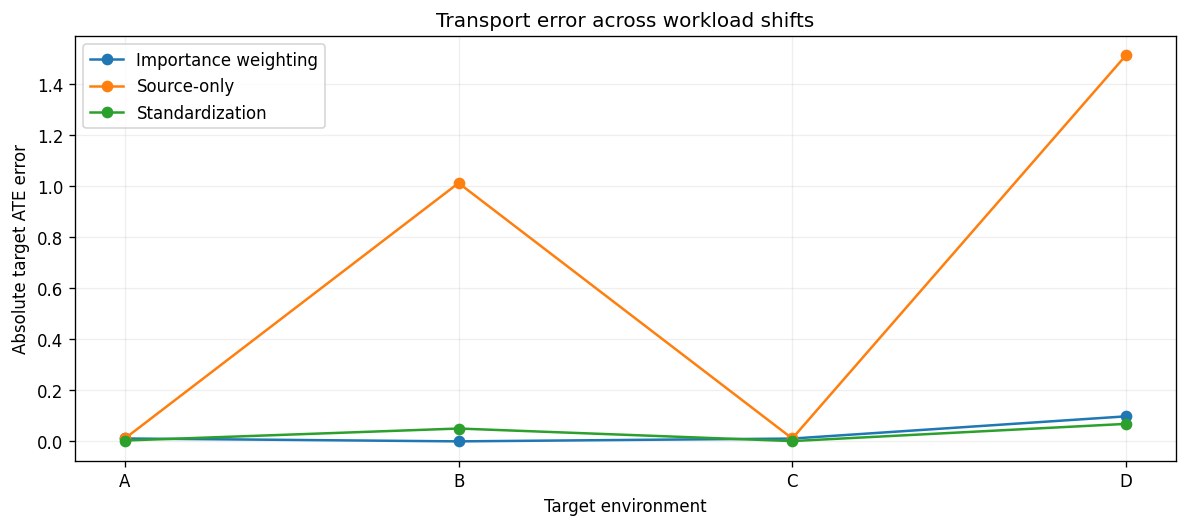

In [4]:
rows=[]; target_data={}
for i,target in enumerate(ENVS):
    test=generate(SEED+100+i,3500,target);target_data[target]=test
    tau_src=effects(beta,source)
    w=gaussian_ratio(source.U.to_numpy(),'A',target)
    methods={'Source-only':float(tau_src.mean()),'Standardization':float(effects(beta,test).mean()),'Importance weighting':float(w@tau_src)}
    for name,estimate in methods.items():
        rows.append(dict(target=target,method=name,ate_hat=estimate,true_ate=oracle_ate(target),absolute_error=abs(estimate-oracle_ate(target)),weight_ess=ess(w) if name=='Importance weighting' else np.nan))
comparison=pd.DataFrame(rows)
display(comparison.round(4));comparison.to_csv(REPORT/'transport_comparison.csv',index=False)
fig,ax=plt.subplots(figsize=(10,4.5))
for name,g in comparison.groupby('method'):
    ax.plot(g.target,g.absolute_error,marker='o',label=name)
ax.set(ylabel='Absolute target ATE error',xlabel='Target environment',title='Transport error across workload shifts');ax.legend();fig.tight_layout();fig.savefig(FIG/'transport_error.png');plt.show()
assert comparison[(comparison.target=='B')&(comparison.method=='Standardization')].absolute_error.iloc[0] < .15

## Effect curves

Check the estimated conditional effect against the exact curve.

The same $\tau(u)$ works for A and B, even though their average effects differ.

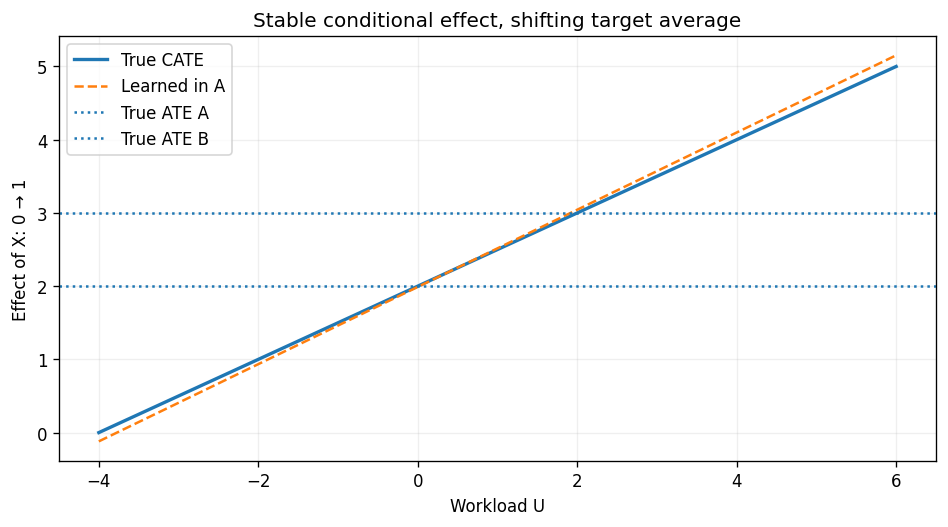

In [5]:
u_grid=np.linspace(-4,6,160)
grid=pd.DataFrame({'X':np.zeros(len(u_grid)),'U':u_grid})
fig,ax=plt.subplots(figsize=(8,4.5))
ax.plot(u_grid,oracle_cate(u_grid),label='True CATE',lw=2)
ax.plot(u_grid,effects(beta,grid),ls='--',label='Learned in A')
for env in ['A','B']:
    ax.axhline(oracle_ate(env),ls=':',label=f'True ATE {env}')
ax.set(xlabel='Workload U',ylabel='Effect of X: 0 → 1',title='Stable conditional effect, shifting target average');ax.legend();fig.tight_layout();fig.savefig(FIG/'cate_transport.png');plt.show()

## Nonlinear transport

Fit the full nonlinear equation in A and transport it to B and C.

$$m(x,u)=\beta_0+\beta_Xx+\beta_Uu+\beta_{XU}xu+\beta_{X^2}x^2+\beta_{\sin}\sin(x).$$

Compare it with the interaction-only model to see what happens when the nonlinear terms are omitted.

,model,target,ate_hat,true_ate,absolute_error
0,Interaction only,A,2.2514,2.8049,0.5535
1,Interaction only,B,3.9266,3.8049,0.1217
2,Interaction only,C,2.3146,2.8049,0.4903
3,Full nonlinear,A,2.8066,2.8049,0.0017
4,Full nonlinear,B,3.7686,3.8049,0.0363
5,Full nonlinear,C,2.8429,2.8049,0.0380


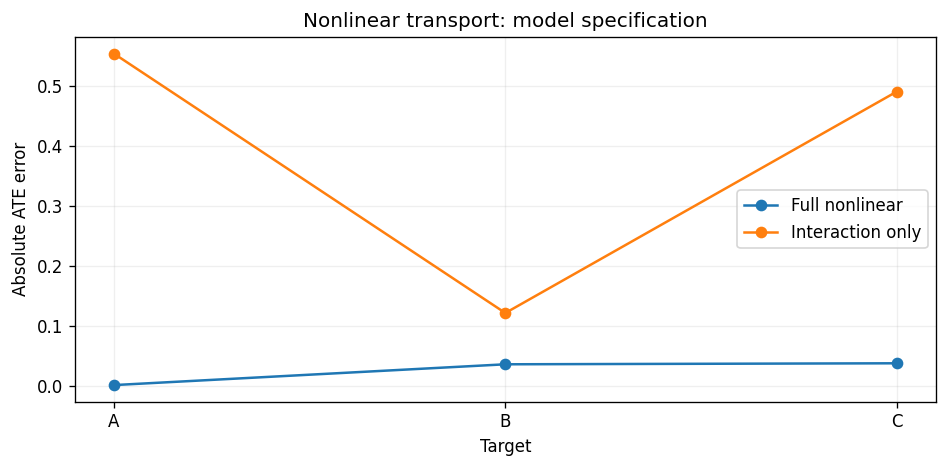

In [6]:
nl_train=generate(SEED+300,6000,'A',nonlinear=True)
nl_rows=[]
for model,nonlin in [('Interaction only',False),('Full nonlinear',True)]:
    b=fit(nl_train,nonlinear=nonlin)
    for i,env in enumerate(['A','B','C']):
        tar=generate(SEED+310+i,3500,env,nonlinear=True)
        hat=float(effects(b,tar,nonlinear=nonlin).mean())
        nl_rows.append(dict(model=model,target=env,ate_hat=hat,true_ate=oracle_ate(env,True),absolute_error=abs(hat-oracle_ate(env,True))))
nl_result=pd.DataFrame(nl_rows);display(nl_result.round(4));nl_result.to_csv(REPORT/'nonlinear_transport.csv',index=False)
fig,ax=plt.subplots(figsize=(8,4))
for name,g in nl_result.groupby('model'):ax.plot(g.target,g.absolute_error,marker='o',label=name)
ax.set(ylabel='Absolute ATE error',xlabel='Target',title='Nonlinear transport: model specification');ax.legend();fig.tight_layout();fig.savefig(FIG/'nonlinear_transport.png');plt.show()

## Noisy workload measurements

In practice, only measure a proxy.

$$W=U+\sigma_W\epsilon_W.$$

Compare standardization using the true workload with standardization using different noise levels in $W$.

Using a noisy proxy in the interaction model changes the fitted effect and its transported average.

,proxy_noise_sd,adjuster,ate_hat,true_ate,absolute_error
0,0.0,U,2.9950,3.0,0.0050
1,0.5,W,3.0691,3.0,0.0691
2,1.0,W,3.0685,3.0,0.0685
3,2.0,W,2.9253,3.0,0.0747


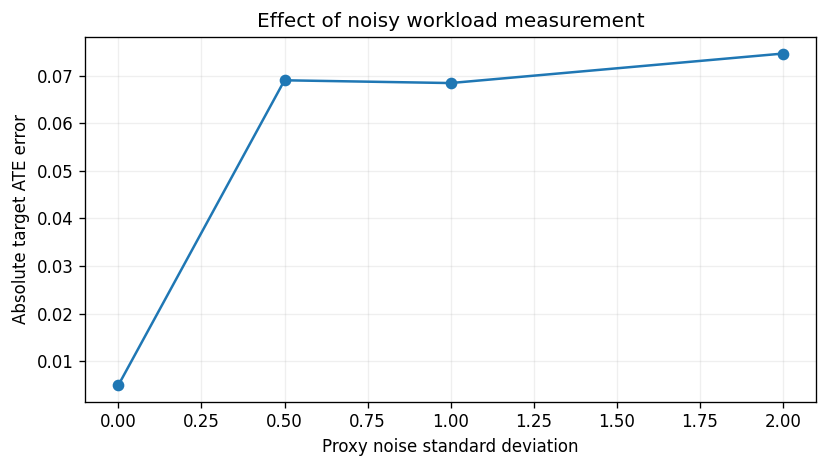

In [7]:
proxy_rows=[]
for noise in [0.,.5,1.,2.]:
    train=generate(SEED+400,5000,'A',proxy_sd=noise)
    test=generate(SEED+401,5000,'B',proxy_sd=noise)
    adjuster='U' if noise==0 else 'W'
    b=fit(train,adjuster=adjuster)
    hat=float(effects(b,test,adjuster=adjuster).mean())
    proxy_rows.append(dict(proxy_noise_sd=noise,adjuster=adjuster,ate_hat=hat,true_ate=oracle_ate('B'),absolute_error=abs(hat-oracle_ate('B'))))
proxy_result=pd.DataFrame(proxy_rows);display(proxy_result.round(4));proxy_result.to_csv(REPORT/'proxy_sensitivity.csv',index=False)
fig,ax=plt.subplots(figsize=(7,4));ax.plot(proxy_result.proxy_noise_sd,proxy_result.absolute_error,marker='o');ax.set(xlabel='Proxy noise standard deviation',ylabel='Absolute target ATE error',title='Effect of noisy workload measurement');fig.tight_layout();fig.savefig(FIG/'proxy_sensitivity.png');plt.show()

## Uncertainty intervals

Use repeated simulation to check more than a single favorable dataset.

For each repeat, we fit the regression in a new source sample and standardize over a new target sample.

Also draw regression coefficients from the Gaussian sampling approximation and bootstrap target workloads. The interval therefore accounts for outcome-model estimation and the finite target sample.

$$\widehat\beta\approx\mathcal N\!\left(\beta,\widehat\sigma^2(Z^TZ)^{-1}\right).$$

We report empirical 95% interval coverage and ATE error over repeated experiments. These are simulation-based frequentist intervals, not Bayesian posterior credible intervals.

,target,repeats,coverage,mean_abs_error,median_interval_width
0,A,60,0.9500,0.0305,0.1616
1,B,60,0.9167,0.0459,0.2456
2,C,60,0.9833,0.0446,0.2210


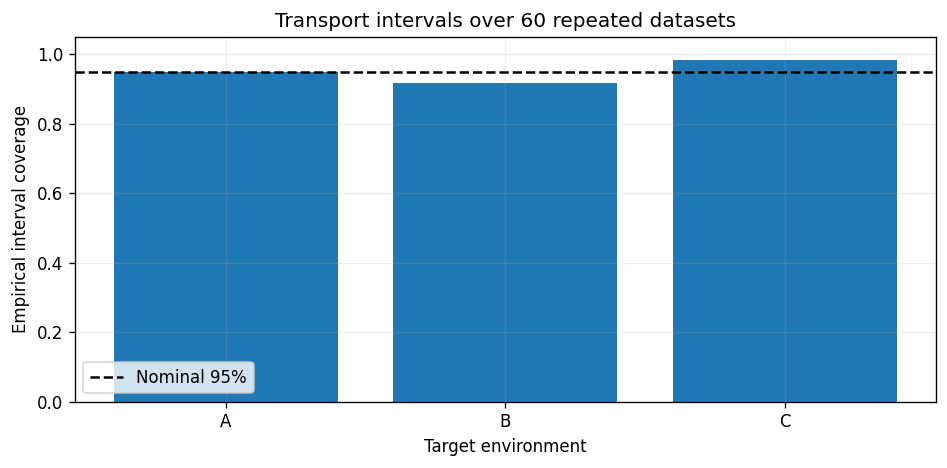

In [8]:
def transport_ci(source_df,target_df,seed,level=.95,draws=600):
    X=design(source_df);y=source_df.Y.to_numpy();XtX=X.T@X
    b=np.linalg.solve(XtX,X.T@y)
    r=y-X@b;s2=float((r@r)/(len(y)-X.shape[1]));cov=s2*np.linalg.inv(XtX)
    rng=np.random.default_rng(int(seed))
    betas=rng.multivariate_normal(b,cov,size=draws)
    means=target_df.U.to_numpy()[rng.integers(0,len(target_df),size=(draws,len(target_df)))].mean(axis=1)
    draws_ate=betas[:,1]+betas[:,3]*means
    ci=np.quantile(draws_ate,[(1-level)/2,1-(1-level)/2])
    return float(np.mean(effects(b,target_df))),float(ci[0]),float(ci[1])

REPS=60
cal=[]
for target in ['A','B','C']:
    for r in range(REPS):
        train=generate(SEED+10000+100*r,800,'A')
        test=generate(SEED+10001+100*r,500,target)
        estimate,lo,hi=transport_ci(train,test,SEED+20000+100*r,draws=400)
        truth=oracle_ate(target)
        cal.append(dict(target=target,rep=r,ate_hat=estimate,lo=lo,hi=hi,true_ate=truth,covered=lo<=truth<=hi,absolute_error=abs(estimate-truth),interval_width=hi-lo))
cal_df=pd.DataFrame(cal)
cal_summary=cal_df.groupby('target').agg(repeats=('rep','size'),coverage=('covered','mean'),mean_abs_error=('absolute_error','mean'),median_interval_width=('interval_width','median')).reset_index()
display(cal_summary.round(4));cal_df.to_csv(REPORT/'repeated_intervals.csv',index=False);cal_summary.to_csv(REPORT/'interval_summary.csv',index=False)
fig,ax=plt.subplots(figsize=(8,4));ax.bar(cal_summary.target,cal_summary.coverage);ax.axhline(.95,color='black',ls='--',label='Nominal 95%');ax.set(ylim=(0,1.05),ylabel='Empirical interval coverage',xlabel='Target environment',title=f'Transport intervals over {REPS} repeated datasets');ax.legend();fig.tight_layout();fig.savefig(FIG/'interval_coverage.png');plt.show()

## Weight stability

Density weighting becomes unstable when target workloads are rare in the source data.

$$\mathrm{ESS}=\frac{(\sum_iw_i)^2}{\sum_iw_i^2}.$$

We compare the weighting error with its effective sample size as the target mean moves farther from A.

,target,median_ess,mean_iw_abs_error,mean_std_abs_error
0,A,1000.000,0.032,0.032
1,B,53.779,0.109,0.045
2,C,252.015,0.146,0.042
3,D,11.430,0.272,0.057


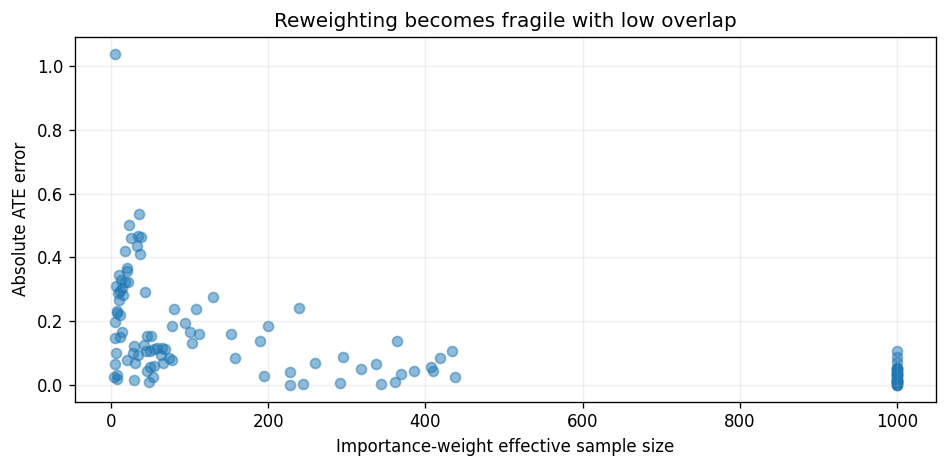

In [9]:
stress=[]
for env in ENVS:
    for r in range(30):
        s=generate(SEED+30000+100*r,1000,'A')
        bs=fit(s);ts=effects(bs,s)
        target=generate(SEED+30001+100*r,800,env)
        w=gaussian_ratio(s.U.to_numpy(),'A',env)
        stress.append(dict(target=env,rep=r,ess=ess(w),iw_abs_error=abs(w@ts-oracle_ate(env)),std_abs_error=abs(effects(bs,target).mean()-oracle_ate(env))))
stress_df=pd.DataFrame(stress)
stress_summary=stress_df.groupby('target').agg(median_ess=('ess','median'),mean_iw_abs_error=('iw_abs_error','mean'),mean_std_abs_error=('std_abs_error','mean')).reset_index()
display(stress_summary.round(3));stress_df.to_csv(REPORT/'weight_stress.csv',index=False)
fig,ax=plt.subplots(figsize=(8,4));ax.scatter(stress_df.ess,stress_df.iw_abs_error,alpha=.5);ax.set(xlabel='Importance-weight effective sample size',ylabel='Absolute ATE error',title='Reweighting becomes fragile with low overlap');fig.tight_layout();fig.savefig(FIG/'weight_stability.png');plt.show()

## Checks and saved results

We check the model against the known SCM rather than judging it only by prediction fit.

Standardization needs workload to be observed and the conditional outcome model to remain valid after the shift.

Importance weighting needs sufficient overlap between source and target workloads.

The proxy experiment shows what changes when workload is measured poorly.

In [10]:
assert len(comparison)==len(ENVS)*3
assert np.isfinite(comparison.ate_hat).all()
assert np.isfinite(cal_df[['ate_hat','lo','hi']]).to_numpy().all()
assert (cal_df.lo < cal_df.hi).all()
assert (stress_df.ess>=1).all() and (stress_df.ess<=1000+1e-6).all()
assert cal_summary.repeats.eq(REPS).all()
manifest={'seed':SEED,'jax_version':jax.__version__,'python':platform.python_version(), 'train_source':'A','environments':ENVS,'repeated_interval_experiments':REPS,'outputs':[str(p) for p in sorted(REPORT.glob('*.csv'))], 'figures':[str(p) for p in sorted(FIG.glob('*.png'))]}
(REPORT/'run_metadata.json').write_text(json.dumps(manifest,indent=2))
print('Passed all checks.')
print('Saved figures:',len(list(FIG.glob('*.png'))),'| CSV reports:',len(list(REPORT.glob('*.csv'))))
print('Key comparison (target B):')
display(comparison[comparison.target=='B'][['method','ate_hat','true_ate','absolute_error','weight_ess']].round(4))
print('Repeated interval coverage:')
display(cal_summary.round(3))

Passed all checks.
Saved figures: 6 | CSV reports: 6
Key comparison (target B):


,method,ate_hat,true_ate,absolute_error,weight_ess
3,Source-only,1.9882,3.0,1.0118,NaN
4,Standardization,3.0507,3.0,0.0507,NaN
5,Importance weighting,3.0005,3.0,0.0005,181.2612


Repeated interval coverage:


,target,repeats,coverage,mean_abs_error,median_interval_width
0,A,60,0.950,0.030,0.162
1,B,60,0.917,0.046,0.246
2,C,60,0.983,0.045,0.221


## Run locally

Install `jax`, `numpy`, `pandas`, `matplotlib`, and `notebook`.

Run the cells in order. The results appear under `causal_transport_outputs/`.

This is a controlled synthetic experiment. The known equations make it possible to check transport estimates, uncertainty, and failure cases directly.